# Quantum RL for Autonomous Cyber Defense

**Final-year engineering project prototype · reproducible CPU simulation**

## Abstract
This notebook builds and evaluates an autonomous defender for a small, synthetic enterprise-network simulator. A variational quantum circuit (VQC) with four default qubits parameterizes a stochastic policy trained by REINFORCE. A transparent rule-based controller and neural DQN and PPO agents provide classical baselines. Results are generated by execution; this notebook contains no pre-filled claims of empirical performance.

**Research question.** Can a small variational quantum policy learn a useful defensive policy in a partially observed toy cyber-defense task, and how does its measured performance and runtime compare with classical baselines under a common evaluation protocol?

> This is a research/education simulation. It neither attacks real infrastructure nor establishes quantum advantage or operational cybersecurity effectiveness.

## Project objectives and scope

- Model defender decisions against stochastic compromise, service degradation, and uncertain telemetry.
- Train a quantum policy by interacting with the simulator and updating circuit parameters through policy gradients.
- Implement working rule-based, DQN, and PPO baselines with a shared environment/reward.
- Measure held-out returns, security and availability outcomes, defensive cost, training curves, and runtimes.
- Keep the default run modest; configure `QUICK_MODE=False` for a larger study.

**Scope decision.** The network is a handful of abstract assets represented by counts and aggregate risk—not a packet simulator, vulnerability database, or digital twin. All dynamics are synthetic. The Q-learning and PPO implementations are intentionally compact and self-contained so their learning logic is inspectable.

## Quantum RL and cyber-defense background

A **qubit** has computational basis states \(|0\rangle\) and \(|1\rangle\), and a normalized state can be a superposition \(\alpha|0\rangle+\beta|1\rangle\), with \(|\alpha|^2+|\beta|^2=1\). Measurement produces a classical outcome probabilistically. Rotation gates (here `RY`) rotate a state by trainable angles. CNOT gates entangle pairs, so joint states can no longer be described as independent qubits.

A **parameterized quantum circuit** applies data-encoding rotations followed by trainable rotations and entanglers. We measure Pauli-Z expectations \(\langle Z_i\rangle\in[-1,1]\), then use a small classical linear head to produce action logits. PennyLane differentiates this hybrid computation; its default analytic simulator computes exact expectation values, not finite-shot samples.

For policy gradient, the agent samples action \(a_t\sim\pi_\theta(\cdot|s_t)\). The discounted return is \(G_t=\sum_{k=0}^{T-t-1}\gamma^k r_{t+k}\). REINFORCE ascends \(\mathbb{E}[\log\pi_\theta(a_t|s_t)(G_t-b)]\), with baseline \(b\) reducing variance. DQN instead learns action values using a Bellman target; PPO constrains policy updates using a clipped importance ratio.

**Concrete example.** If normalized telemetry suggests elevated confidence and compromises, an encoding rotation changes the circuit state; measurements change the logits and the policy may sample isolation. The environment then applies the action, attacker dynamics occur, and the reward joins the episode trajectory for learning.

## System architecture

```text
Hidden network + attacker ──observe──> 8 bounded features
          ▲                                  │
          │                           feature compression
          │                         (8 → 4 or 6 values)
          │                                  ▼
transition / reward <── action ── policy: VQC / DQN / PPO / rules
          │                                  ▲
          └── next observation, reward ── training update
                                                │
                REINFORCE / TD replay / PPO <────┘

Evaluation: frozen policy + identical held-out episode seeds → metrics/plots
```

The hidden state drives transitions; only aggregate observations reach the agents. The encoder maps every feature using a learned, seeded projection before `RY` angle embedding, so no observation fields are silently discarded. Evaluation uses fresh fixed seeds and disables optimizer updates.

## Colab setup and dependency installation

Run this cell first in a fresh Google Colab CPU runtime. The install command pins the numerical stack used by this notebook and avoids unnecessary dependency upgrades. Colab may still print warnings about unrelated preinstalled packages such as JAX, Dopamine, or `dm-tree`; those packages are not imported or required here. PennyLane and PyTorch are pinned to mutually compatible Python packages; Gymnasium supplies the standard environment API. The notebook uses standard CPU operations only. The finite-shot mode can be slower and stochastic; analytic expectations are the default.

In [3]:
%pip -q uninstall -y jax jaxlib
%pip -q install --upgrade --upgrade-strategy only-if-needed "numpy==2.0.2" "gymnasium==0.29.1" "pennylane==0.40.0" "autoray==0.6.12" "torch>=2.2,<3" "matplotlib>=3.7,<4" "pandas>=2.0,<3"


## Imports, configuration, and random seeds

One seed controls Python, NumPy, and Torch initialization. Each experiment receives explicit training and evaluation seeds. Rerunning the notebook with the same package versions, configuration, and seeds should reproduce the analytic simulator results as closely as the backend allows. Timing is inherently machine-dependent.

In [4]:
import os, random, time, copy, json, math
from collections import deque
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
import gymnasium as gym
from gymnasium import spaces
import pennylane as qml
from IPython.display import display

DEVICE = torch.device("cpu")
ARTIFACT_DIR = Path("quantum_cyber_defender_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

@dataclass
class ExperimentConfig:
    n_qubits: int = 4
    circuit_depth: int = 2
    shots: int | None = None       # None = analytic expectation values
    gamma: float = 0.97
    quantum_episodes: int = 120
    dqn_episodes: int = 160
    ppo_episodes: int = 160
    eval_episodes: int = 30
    seeds: tuple = (11, 23, 37)
    max_steps: int = 40
    learning_rate: float = 0.015
    dqn_learning_rate: float = 0.001
    ppo_learning_rate: float = 0.001
    quick_mode: bool = True

CONFIG = ExperimentConfig()
if CONFIG.quick_mode:
    CONFIG.quantum_episodes = 60
    CONFIG.dqn_episodes = 80
    CONFIG.ppo_episodes = 80
    CONFIG.eval_episodes = 12
    CONFIG.seeds = (11, 23)
set_seed(7)
print(CONFIG)
print("Torch:", torch.__version__, "PennyLane:", qml.__version__, "Device:", DEVICE)

ExperimentConfig(n_qubits=4, circuit_depth=2, shots=None, gamma=0.97, quantum_episodes=60, dqn_episodes=80, ppo_episodes=80, eval_episodes=12, seeds=(11, 23), max_steps=40, learning_rate=0.015, dqn_learning_rate=0.001, ppo_learning_rate=0.001, quick_mode=True)
Torch: 2.14.1+cu130 PennyLane: 0.40.0 Device: cpu


## Cyber-defense environment implementation

`CyberDefenseEnv` has six assets and an aggregate hidden state: which assets are compromised/contained/hardened, service health, threat severity, resources, and time. The fixed 8-value observation is bounded in `[0,1]`: compromise fraction, suspicious activity, availability, severity, resource fraction, containment fraction, recovery-needed fraction, and detection confidence. Suspicious activity and confidence are noisy observations; the rest are observable aggregates.

Actions are `0 monitor`, `1 isolate`, `2 restore`, and `3 harden`. Isolation requires a compromise and costs resources; restore is useful only after containment/availability damage; hardening reduces exposure and future compromise risk; monitoring costs a small resource amount but improves telemetry. Invalid/unhelpful actions still consume a turn and incur a modest cost, rather than triggering exceptions. The attacker can compromise uncontained assets, increase severity, and degrade availability stochastically.

Reward components are explicit: availability and security improvement are positive, compromised assets/severity and defensive resource spending are penalized, successful containment/recovery has a bonus, and delay under severe threat is penalized. Weight choices are hypotheses, not guarantees of a winner.

In [5]:
N_FEATURES = 8
N_ACTIONS = 4
ACTION_NAMES = {0: "monitor", 1: "isolate", 2: "restore", 3: "harden"}

class CyberDefenseEnv(gym.Env):
    """Synthetic, partially observed cyber-defense simulator; no real network actions."""
    metadata = {"render_modes": []}
    def __init__(self, max_steps=40, n_assets=6):
        super().__init__()
        self.max_steps, self.n_assets = int(max_steps), int(n_assets)
        self.action_space = spaces.Discrete(N_ACTIONS)
        self.observation_space = spaces.Box(0.0, 1.0, shape=(N_FEATURES,), dtype=np.float32)
        self.rng = np.random.default_rng()

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.rng = np.random.default_rng(seed)
        self.compromised = np.zeros(self.n_assets, dtype=bool)
        self.contained = np.zeros(self.n_assets, dtype=bool)
        self.hardened = np.zeros(self.n_assets, dtype=bool)
        self.availability = 1.0
        self.severity = float(self.rng.uniform(0.15, 0.35))
        self.resources = 1.0
        self.confidence = float(self.rng.uniform(0.25, 0.5))
        self.suspicious = float(self.rng.uniform(0.05, 0.2))
        self.t = 0
        return self._observation(), self._info()

    def _observation(self):
        return np.array([
            self.compromised.mean(), self.suspicious, self.availability,
            self.severity, self.resources, self.contained.mean(),
            float(np.any(self.contained & self.compromised)), self.confidence
        ], dtype=np.float32)

    def _info(self):
        return {"compromised_count": int(self.compromised.sum()),
                "availability": float(self.availability), "severity": float(self.severity),
                "resources": float(self.resources), "contained_count": int(self.contained.sum()),
                "action_cost": float(getattr(self, "last_cost", 0.0))}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Action must be an integer in [0,{N_ACTIONS-1}]")
        action = int(action)
        old_comp = int(self.compromised.sum())
        old_avail = self.availability
        old_severity = self.severity
        old_contained = int(self.contained.sum())
        self.t += 1
        cost = 0.0
        success = False

        if action == 0:  # monitor: better confidence, modest cost
            cost = 0.012
            self.confidence = min(1.0, self.confidence + self.rng.uniform(0.18, 0.38))
            self.suspicious = min(1.0, 0.45*self.suspicious + 0.5*self.compromised.mean() + self.rng.uniform(0.0, 0.12))
            self.severity = max(0.0, self.severity - 0.035)
        elif action == 1:  # isolate one suspected compromised asset
            cost = 0.075
            candidates = np.flatnonzero(self.compromised & ~self.contained)
            if candidates.size and self.rng.random() < self.confidence:
                idx = int(candidates[np.argmax(self.hardened[candidates] == False)])
                self.contained[idx] = True
                self.availability = max(0.25, self.availability - 0.09)
                self.severity = max(0.0, self.severity - 0.18)
                success = True
            else:
                self.severity = min(1.0, self.severity + 0.025)
        elif action == 2:  # restore only contained assets or damaged service
            cost = 0.09
            candidates = np.flatnonzero(self.contained & self.compromised)
            if candidates.size:
                idx = int(candidates[0]); self.compromised[idx] = False; self.contained[idx] = False
                self.availability = min(1.0, self.availability + 0.13)
                self.severity = max(0.0, self.severity - 0.08)
                success = True
            elif self.availability < 0.96:
                self.availability = min(1.0, self.availability + 0.12)
                success = True
            else:
                cost = 0.025
        elif action == 3:  # harden one asset; reduce future risk
            cost = 0.055
            candidates = np.flatnonzero(~self.hardened & ~self.compromised)
            if candidates.size:
                self.hardened[int(candidates[0])] = True
                self.severity = max(0.0, self.severity - 0.06)
                success = True

        self.resources = max(0.0, self.resources - cost)
        self.last_cost = cost
        # Stochastic attacker/environment: contained assets cannot be newly compromised.
        exposed = np.flatnonzero(~self.compromised & ~self.contained)
        attack_pressure = 0.025 + 0.10*self.severity + 0.06*self.suspicious
        if exposed.size and self.rng.random() < attack_pressure:
            weights = np.where(self.hardened[exposed], 0.3, 1.0)
            idx = int(self.rng.choice(exposed, p=weights/weights.sum()))
            self.compromised[idx] = True
            self.severity = min(1.0, self.severity + 0.12)
            self.availability = max(0.25, self.availability - 0.07)
        if self.compromised.any() and self.rng.random() < 0.18*self.compromised.mean():
            self.availability = max(0.25, self.availability - 0.035)
            self.severity = min(1.0, self.severity + 0.035)
        self.suspicious = float(np.clip(0.6*self.suspicious + 0.25*self.severity + self.rng.normal(0, 0.07), 0, 1))
        self.confidence = float(np.clip(0.86*self.confidence + self.rng.normal(0, 0.035), 0, 1))
        self.severity = float(np.clip(self.severity, 0, 1))

        new_comp = int(self.compromised.sum())
        security_gain = old_comp - new_comp
        availability_gain = self.availability - old_avail
        threat_gain = old_severity - self.severity
        reward = (0.55*security_gain + 0.22*availability_gain + 0.18*threat_gain
                  + 0.13*float(success) - 0.09*new_comp/self.n_assets
                  - 0.035*self.severity - 0.16*cost)
        if self.severity > 0.72 and action in (0, 3):
            reward -= 0.035
        terminated = bool(self.compromised.all() or self.availability <= 0.26)
        truncated = bool(self.t >= self.max_steps and not terminated)
        if terminated:
            reward -= 0.7
        return self._observation(), float(reward), terminated, truncated, self._info()


def make_env(seed=None, max_steps=None):
    env = CyberDefenseEnv(max_steps=max_steps or CONFIG.max_steps)
    obs, info = env.reset(seed=seed)
    return env, obs, info

## Environment demonstrations and tests

The checks verify Gymnasium's reset/step signatures, bounds, invalid-action handling, reproducibility for matching seeds, reward direction for an available recovery action, and horizon truncation. We use the built-in checker with rendering checks disabled. The tests are deterministic sanity tests, not proof that the model represents a real network.

In [6]:
from gymnasium.utils.env_checker import check_env

def test_environment():
    env = CyberDefenseEnv(max_steps=3)
    check_env(env, skip_render_check=True)
    a, _ = env.reset(seed=123); b, _ = env.reset(seed=123)
    assert np.allclose(a, b) and a.shape == (N_FEATURES,)
    assert env.observation_space.contains(a)
    try: env.step(99); raise AssertionError("Invalid action accepted")
    except ValueError: pass
    env.reset(seed=4)
    # Damaged availability makes restore useful.
    env.availability = 0.6
    _, reward, term, trunc, info = env.step(2)
    assert info["availability"] > 0.6 and reward > -1
    env.reset(seed=5)
    for _ in range(3): result = env.step(0)
    assert result[3] is True
    env_a, _, _ = make_env(seed=98); env_b, _, _ = make_env(seed=98)
    for action in [0, 3, 1, 2]:
        ra = env_a.step(action); rb = env_b.step(action)
        assert np.allclose(ra[0], rb[0]) and ra[1:4] == rb[1:4]
    print("Environment tests passed; Gymnasium checker passed.")

test_environment()
env, obs, _ = make_env(seed=9)
print("Initial observation:", obs)
for act in [0, 3, 1]:
    obs, reward, terminated, truncated, info = env.step(act)
    print(ACTION_NAMES[act], "reward=", round(reward, 3), "info=", info)
    if terminated or truncated: break

Environment tests passed; Gymnasium checker passed.
Initial observation: [0.         0.14047222 1.         0.32404983 1.         0.
 0.         0.3217043 ]
monitor reward= -0.006 info= {'compromised_count': 0, 'availability': 1.0, 'severity': 0.28904984079401685, 'resources': 0.988, 'contained_count': 0, 'action_cost': 0.012}
harden reward= -0.482 info= {'compromised_count': 1, 'availability': 0.9299999999999999, 'severity': 0.34904984079401685, 'resources': 0.9329999999999999, 'contained_count': 0, 'action_cost': 0.055}
isolate reward= -0.045 info= {'compromised_count': 1, 'availability': 0.9299999999999999, 'severity': 0.3740498407940169, 'resources': 0.858, 'contained_count': 0, 'action_cost': 0.075}


## Quantum circuit fundamentals

There are eight observation values but only four default qubits (six is optional). To use all eight features without dropping any, a seeded learnable linear projection maps 8 inputs to `n_qubits` values; `tanh` bounds them, and each becomes an `RY` angle. The projection is a classical feature map and is trained with the quantum parameters. Then each layer applies trainable `RY` and `RZ` rotations and a ring of CNOTs. Each qubit returns a Pauli-Z expectation.

The hybrid model has a linear action head. It converts `n_qubits` expectation values into four logits, then softmax defines a valid action distribution. A qubit is not a classical bit containing many values; the simulator represents amplitudes and measurement statistics. Four qubits are enough to test a hybrid differentiable policy cheaply, while six changes capacity and compute modestly. Neither size is evidence of advantage. Finite-shot estimates introduce sampling noise; the default analytic simulator computes exact expectations.

## Quantum policy implementation

`default.qubit` is PennyLane's CPU simulator. With `shots=None`, the QNode returns analytic expectations. When configured with an integer number of shots, the circuit samples measurement outcomes and estimates those expectations. PennyLane's Torch interface differentiates the expectation calculation, and Adam updates both encoder/head and circuit parameters.

**Gradient check.** The test below requires finite output, proper probability normalization, and a finite nonzero gradient through circuit parameters. PennyLane uses simulator differentiation (typically parameter-shift rules for this device/interface); this computes gradients without hardware access.

In [7]:
class QuantumPolicy(nn.Module):
    def __init__(self, n_features=N_FEATURES, n_actions=N_ACTIONS, n_qubits=4,
                 depth=2, shots=None, seed=7):
        super().__init__()
        if n_qubits not in (4, 6): raise ValueError("Prototype supports 4 or 6 qubits")
        self.n_qubits, self.depth, self.shots = n_qubits, depth, shots
        self.encoder = nn.Linear(n_features, n_qubits)
        self.head = nn.Linear(n_qubits, n_actions)
        generator = torch.Generator().manual_seed(seed)
        with torch.no_grad():
            self.encoder.weight.copy_(torch.randn(self.encoder.weight.shape, generator=generator)*0.25)
            self.encoder.bias.zero_()
            self.head.weight.copy_(torch.randn(self.head.weight.shape, generator=generator)*0.15)
            self.head.bias.zero_()
        self.dev = qml.device("default.qubit", wires=n_qubits, shots=shots, seed=seed)
        @qml.qnode(self.dev, interface="torch", diff_method="parameter-shift")
        def circuit(inputs, weights):
            for wire in range(n_qubits): qml.RY(inputs[wire], wires=wire)
            for layer in range(depth):
                for wire in range(n_qubits):
                    qml.RY(weights[layer, wire, 0], wires=wire)
                    qml.RZ(weights[layer, wire, 1], wires=wire)
                for wire in range(n_qubits): qml.CNOT(wires=[wire, (wire+1) % n_qubits])
            return [qml.expval(qml.PauliZ(wire)) for wire in range(n_qubits)]
        self.circuit = circuit
        self.q_weights = nn.Parameter(torch.empty(depth, n_qubits, 2))
        torch.nn.init.uniform_(self.q_weights, -0.3, 0.3)

    def forward(self, observations):
        if not torch.is_tensor(observations):
            observations = torch.as_tensor(observations, dtype=torch.float32)
        observations = observations.to(dtype=torch.float32, device=DEVICE)
        single = observations.ndim == 1
        if single: observations = observations.unsqueeze(0)
        outputs = []
        for obs in observations:
            encoded = torch.tanh(self.encoder(obs)) * math.pi
            measured = self.circuit(encoded, self.q_weights)
            outputs.append(torch.stack(list(measured)).to(dtype=torch.float32))
        quantum_features = torch.stack(outputs)
        logits = self.head(quantum_features)
        return logits.squeeze(0) if single else logits

    def probabilities(self, observation):
        return torch.softmax(self.forward(observation), dim=-1)


def test_quantum_policy():
    set_seed(3)
    policy = QuantumPolicy(n_qubits=4, depth=2, shots=None, seed=3)
    obs = torch.tensor([0.2, 0.4, 0.8, 0.3, 0.9, 0.0, 0.0, 0.5])
    probs = policy.probabilities(obs)
    assert probs.shape == (N_ACTIONS,) and torch.isfinite(probs).all()
    assert torch.all(probs >= 0) and torch.allclose(probs.sum(), torch.tensor(1.0), atol=1e-6)
    loss = -torch.log(probs[1]); loss.backward()
    grad = policy.q_weights.grad
    assert grad is not None and torch.isfinite(grad).all() and grad.norm().item() > 1e-9
    print("Quantum policy output/gradient tests passed; probs:", probs.detach().numpy())

test_quantum_policy()
policy_demo = QuantumPolicy(n_qubits=CONFIG.n_qubits, depth=CONFIG.circuit_depth, shots=CONFIG.shots)
print(qml.draw(policy_demo.circuit)(torch.zeros(CONFIG.n_qubits), policy_demo.q_weights.detach()))

Quantum policy output/gradient tests passed; probs: [0.25735128 0.22413927 0.25857994 0.2599295 ]
0: ──RY(0.00)──RY(-0.06)──RZ(0.02)──╭●───────╭X──RY(0.14)───RZ(0.17)──╭●───────╭X─┤  <Z>
1: ──RY(0.00)──RY(0.27)───RZ(0.00)──╰X─╭●────│───RY(-0.28)──RZ(-0.04)─╰X─╭●────│──┤  <Z>
2: ──RY(0.00)──RY(0.15)───RZ(-0.07)────╰X─╭●─│───RY(-0.29)──RZ(0.00)─────╰X─╭●─│──┤  <Z>
3: ──RY(0.00)──RY(-0.23)──RZ(0.06)────────╰X─╰●──RY(0.01)───RZ(0.10)────────╰X─╰●─┤  <Z>


## Quantum policy-gradient training

The training loop gathers one complete trajectory at a time and computes returns backward: `G_t = r_t + gamma * G_(t+1)`, with the last return reset at either termination or truncation. It normalizes returns within the episode when there is variation; otherwise it leaves them unchanged. The policy loss is the negative log-probability-weighted return minus an entropy bonus. The entropy term encourages exploration early, but a small coefficient avoids forcing randomness forever.

Evaluation is a separate function using greedy actions and `torch.no_grad()`. The smoke test runs short actual environment episodes and asserts that trainable circuit parameters change. Episode budgets and episode length bound simulator cost; increasing qubits, depth, or shots increases runtime.

In [8]:
def obs_tensor(obs): return torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)

def discounted_returns(rewards, gamma):
    out, running = [], 0.0
    for reward in reversed(rewards):
        running = float(reward) + gamma*running
        out.append(running)
    return torch.tensor(list(reversed(out)), dtype=torch.float32)

def train_quantum(env_factory, episodes=60, seed=11, n_qubits=4, depth=2, shots=None,
                  gamma=0.97, lr=0.015, entropy_coef=0.01):
    set_seed(seed)
    env = env_factory()
    policy = QuantumPolicy(n_qubits=n_qubits, depth=depth, shots=shots, seed=seed)
    optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    history, start = [], time.perf_counter()
    for episode in range(episodes):
        obs, _ = env.reset(seed=seed*1000 + episode)
        log_probs, entropies, rewards = [], [], []
        while True:
            distribution = Categorical(logits=policy(obs_tensor(obs)))
            action = distribution.sample()
            log_probs.append(distribution.log_prob(action))
            entropies.append(distribution.entropy())
            obs, reward, terminated, truncated, _ = env.step(int(action.item()))
            rewards.append(reward)
            if terminated or truncated: break
        returns = discounted_returns(rewards, gamma)
        if returns.numel() > 1 and returns.std(unbiased=False) > 1e-6:
            returns = (returns - returns.mean())/(returns.std(unbiased=False)+1e-8)
        log_probs = torch.stack(log_probs); entropies = torch.stack(entropies)
        loss = -(log_probs*returns).mean() - entropy_coef*entropies.mean()
        if not torch.isfinite(loss): raise FloatingPointError("Non-finite quantum policy loss")
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 2.0)
        optimizer.step()
        history.append({"episode": episode+1, "return": float(sum(rewards)), "length": len(rewards), "loss": float(loss.detach())})
    return policy, pd.DataFrame(history), time.perf_counter()-start

def evaluate_quantum(policy, env_factory, seeds):
    policy.eval(); records=[]
    with torch.no_grad():
        for seed in seeds:
            env=env_factory(); obs,_=env.reset(seed=int(seed)); total=0.; costs=[]; comps=[]; avails=[]; lengths=0
            while True:
                action=int(torch.argmax(policy(obs_tensor(obs))).item())
                obs,reward,term,trunc,info=env.step(action); total+=reward; lengths+=1
                costs.append(info["action_cost"]); comps.append(info["compromised_count"]); avails.append(info["availability"])
                if term or trunc: break
            records.append({"return":total,"final_compromised":comps[-1],"mean_compromised":np.mean(comps),
                            "mean_availability":np.mean(avails),"action_cost":sum(costs),"length":lengths,
                            "terminated":term})
    return pd.DataFrame(records)

def test_quantum_training_smoke():
    before_seed=17
    set_seed(before_seed)
    model=QuantumPolicy(n_qubits=4, depth=1, seed=before_seed)
    before=model.q_weights.detach().clone()
    trained, hist, _=train_quantum(lambda: CyberDefenseEnv(max_steps=5), episodes=2, seed=before_seed,
                                    n_qubits=4, depth=1, gamma=.95, lr=.02)
    assert len(hist)==2 and not torch.allclose(before, trained.q_weights.detach())
    assert np.isfinite(hist["return"]).all()
    print("REINFORCE interaction/parameter-update smoke test passed.")

test_quantum_training_smoke()

REINFORCE interaction/parameter-update smoke test passed.


## Rule-based baseline

This controller is a reasonable transparent heuristic: monitor when confidence is low under suspicious activity, isolate uncontained compromises when sufficiently confident, restore contained or damaged service, and otherwise harden. It has no learning or access to hidden variables. Its fixed thresholds make it interpretable, but cannot adapt to the stochastic dynamics or infer an optimal policy.

In [9]:
def rule_action(obs):
    compromised, suspicious, availability, severity, resources, contained, recovery, confidence = obs
    if recovery > 0 or (availability < 0.88 and contained > 0): return 2
    if compromised > 0 and confidence > 0.48 and resources > 0.12: return 1
    if suspicious > 0.24 and confidence < 0.58 and resources > 0.1: return 0
    if availability < 0.78: return 2
    if resources > 0.16: return 3
    return 0

def evaluate_rule(env_factory, seeds):
    rows=[]
    for seed in seeds:
        env=env_factory(); obs,_=env.reset(seed=int(seed)); total=0.; costs=[]; comps=[]; avails=[]; t=0
        while True:
            obs,reward,term,trunc,info=env.step(rule_action(obs)); total+=reward; t+=1
            costs.append(info["action_cost"]); comps.append(info["compromised_count"]); avails.append(info["availability"])
            if term or trunc: break
        rows.append({"return":total,"final_compromised":comps[-1],"mean_compromised":np.mean(comps),
                     "mean_availability":np.mean(avails),"action_cost":sum(costs),"length":t,"terminated":term})
    return pd.DataFrame(rows)

env,_=CyberDefenseEnv().reset(seed=2)
print("Rule action for initial observation:", ACTION_NAMES[rule_action(env)])

Rule action for initial observation: harden


## DQN implementation and training

DQN approximates action values \(Q(s,a)\). A replay buffer breaks temporal correlations by sampling old transitions. The target network is updated periodically for a more stable Bellman target: \(y=r+\gamma(1-d)\max_{a'}Q_{target}(s',a')\), where `d` marks either termination or truncation. An epsilon-greedy behavior policy explores early and decays toward exploitation.

The network is small (two hidden layers), and learning begins after a modest replay warm-up. Episode-ending flags correctly stop bootstrapping at both termination and time-limit truncation for this finite-horizon task. DQN and PPO are implemented in PyTorch so the same custom environment can be used without an additional wrapper.

In [10]:
class ReplayBuffer:
    def __init__(self, capacity=10000): self.data=deque(maxlen=capacity)
    def add(self, transition): self.data.append(transition)
    def sample(self, batch_size):
        batch=random.sample(self.data, batch_size)
        s,a,r,ns,d=map(np.array, zip(*batch))
        return (torch.tensor(s,dtype=torch.float32),torch.tensor(a,dtype=torch.long),
                torch.tensor(r,dtype=torch.float32),torch.tensor(ns,dtype=torch.float32),
                torch.tensor(d,dtype=torch.float32))
    def __len__(self): return len(self.data)

class QNetwork(nn.Module):
    def __init__(self):
        super().__init__(); self.net=nn.Sequential(nn.Linear(N_FEATURES,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,N_ACTIONS))
    def forward(self,x): return self.net(x)

def train_dqn(env_factory, episodes=80, seed=11, gamma=.97, lr=.001, batch_size=32):
    set_seed(seed); env=env_factory(); online=QNetwork(); target=copy.deepcopy(online)
    optimizer=torch.optim.Adam(online.parameters(),lr=lr); replay=ReplayBuffer()
    history=[]; steps=0; start=time.perf_counter(); target_update=100
    for ep in range(episodes):
        obs,_=env.reset(seed=seed*1000+ep); total=0.; length=0
        epsilon=max(.05, 1.0-.95*ep/max(1,episodes-1))
        while True:
            steps+=1; length+=1
            if random.random()<epsilon: action=env.action_space.sample()
            else:
                with torch.no_grad(): action=int(online(obs_tensor(obs)).argmax().item())
            next_obs,reward,term,trunc,_=env.step(action); done=term or trunc
            replay.add((obs,action,reward,next_obs,float(done))); obs=next_obs; total+=reward
            if len(replay)>=batch_size:
                states,actions,rewards,next_states,dones=replay.sample(batch_size)
                q=online(states).gather(1,actions.unsqueeze(1)).squeeze(1)
                with torch.no_grad(): target_q=rewards+gamma*(1-dones)*target(next_states).max(1).values
                loss=nn.functional.smooth_l1_loss(q,target_q)
                optimizer.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(online.parameters(),5.); optimizer.step()
            if steps%target_update==0: target.load_state_dict(online.state_dict())
            if done: break
        history.append({"episode":ep+1,"return":total,"length":length,"epsilon":epsilon})
    return online,pd.DataFrame(history),time.perf_counter()-start

def evaluate_dqn(model, env_factory, seeds):
    rows=[]; model.eval()
    for seed in seeds:
        env=env_factory(); obs,_=env.reset(seed=int(seed)); total=0.; costs=[]; comps=[]; avails=[]; t=0
        while True:
            with torch.no_grad(): action=int(model(obs_tensor(obs)).argmax().item())
            obs,reward,term,trunc,info=env.step(action); total+=reward; t+=1
            costs.append(info["action_cost"]); comps.append(info["compromised_count"]); avails.append(info["availability"])
            if term or trunc: break
        rows.append({"return":total,"final_compromised":comps[-1],"mean_compromised":np.mean(comps),
                     "mean_availability":np.mean(avails),"action_cost":sum(costs),"length":t,"terminated":term})
    return pd.DataFrame(rows)

# Minimal functional update check: training creates transitions and runs Bellman optimization.
def test_dqn_smoke():
    model, hist, _=train_dqn(lambda: CyberDefenseEnv(max_steps=6),episodes=3,seed=5,batch_size=4)
    assert len(hist)==3 and np.isfinite(hist["return"]).all()
    assert any(p.grad is not None for p in model.parameters())
    print("DQN replay/optimization smoke test passed.")

test_dqn_smoke()

DQN replay/optimization smoke test passed.


## PPO implementation and training

PPO uses a shared actor-critic network. The actor defines a categorical action distribution; the critic estimates state value. At each trajectory, generalized advantage estimation computes \(\delta_t=r_t+\gamma V(s_{t+1})-V(s_t)\) and recursively smooths these TD residuals with \(\lambda\). For multiple epochs, the clipped objective uses \(r_t(\theta)=\exp(\log\pi_\theta(a_t|s_t)-\log\pi_{old}(a_t|s_t))\) and `min(r*A, clip(r)*A)`. A value loss and entropy bonus accompany the actor loss.

This compact on-policy variant collects one episode, then performs minibatch optimization epochs on that trajectory. It is functional PPO, but unlike production PPO packages it has no vectorized environments or elaborate rollout buffering. That simplicity improves inspectability and is a potential sample-efficiency limitation.

In [11]:
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__(); self.base=nn.Sequential(nn.Linear(N_FEATURES,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh())
        self.actor=nn.Linear(64,N_ACTIONS); self.critic=nn.Linear(64,1)
    def forward(self,x):
        h=self.base(x); return self.actor(h),self.critic(h).squeeze(-1)

def train_ppo(env_factory, episodes=80, seed=11, gamma=.97, lr=.001, clip=.2, epochs=4, lam=.95):
    set_seed(seed); env=env_factory(); model=ActorCritic(); optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]; start=time.perf_counter()
    for ep in range(episodes):
        obs,_=env.reset(seed=seed*1000+ep); states=[]; actions=[]; old_logs=[]; rewards=[]; dones=[]; values=[]; total=0.; length=0
        while True:
            s=obs_tensor(obs)
            logits,value=model(s); dist=Categorical(logits=logits); action=dist.sample()
            next_obs,reward,term,trunc,_=env.step(int(action.item())); done=term or trunc
            states.append(s); actions.append(action); old_logs.append(dist.log_prob(action).detach()); values.append(value.detach())
            rewards.append(reward); dones.append(float(done)); obs=next_obs; total+=reward; length+=1
            if done: break
        with torch.no_grad():
            next_value=torch.zeros(()) if (term or trunc) else model(obs_tensor(obs))[1]
            advantages=[]; gae=0.
            for i in reversed(range(len(rewards))):
                nv=next_value if i==len(rewards)-1 else values[i+1]
                mask=1.-dones[i]
                delta=rewards[i]+gamma*nv*mask-values[i]
                gae=delta+gamma*lam*mask*gae
                advantages.append(gae)
            advantages=torch.stack(list(reversed(advantages)))
            returns=advantages+torch.stack(values)
            if advantages.numel()>1: advantages=(advantages-advantages.mean())/(advantages.std(unbiased=False)+1e-8)
        states=torch.stack(states); actions=torch.stack(actions); old_logs=torch.stack(old_logs)
        n=len(rewards); batch=min(32,n)
        for _ in range(epochs):
            indices=torch.randperm(n)
            for ids in indices.split(batch):
                logits, vals=model(states[ids]); dist=Categorical(logits=logits)
                new_logs=dist.log_prob(actions[ids]); ratio=torch.exp(new_logs-old_logs[ids])
                objective=torch.minimum(ratio*advantages[ids],torch.clamp(ratio,1-clip,1+clip)*advantages[ids])
                policy_loss=-objective.mean(); value_loss=nn.functional.mse_loss(vals,returns[ids])
                entropy=dist.entropy().mean(); loss=policy_loss+.5*value_loss-.01*entropy
                optimizer.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.); optimizer.step()
        history.append({"episode":ep+1,"return":total,"length":length})
    return model,pd.DataFrame(history),time.perf_counter()-start

def evaluate_ppo(model, env_factory, seeds):
    rows=[]; model.eval()
    for seed in seeds:
        env=env_factory(); obs,_=env.reset(seed=int(seed)); total=0.; costs=[]; comps=[]; avails=[]; t=0
        while True:
            with torch.no_grad(): action=int(model(obs_tensor(obs))[0].argmax().item())
            obs,reward,term,trunc,info=env.step(action); total+=reward; t+=1
            costs.append(info["action_cost"]); comps.append(info["compromised_count"]); avails.append(info["availability"])
            if term or trunc: break
        rows.append({"return":total,"final_compromised":comps[-1],"mean_compromised":np.mean(comps),
                     "mean_availability":np.mean(avails),"action_cost":sum(costs),"length":t,"terminated":term})
    return pd.DataFrame(rows)

def test_ppo_smoke():
    model,hist,_=train_ppo(lambda: CyberDefenseEnv(max_steps=6),episodes=3,seed=8,epochs=2)
    assert len(hist)==3 and np.isfinite(hist["return"]).all()
    assert any(p.grad is not None for p in model.parameters())
    print("PPO trajectory/optimization smoke test passed.")

test_ppo_smoke()

PPO trajectory/optimization smoke test passed.


## Evaluation protocol

Training and evaluation use independent seed ranges. The same `EVAL_SEEDS` are used for all four methods, making initial conditions and random-number sequences comparable. Because policies take different actions, their later environment random streams need not remain identical; this is a paired-seed protocol, not a counterfactual-identical trajectory guarantee.

Evaluation is frozen: greedy decisions for learned agents, no optimizer calls, no gradient tracking. Metrics include episode return, final and average compromised asset counts, average service availability, cumulative defensive resource costs, episode length, and catastrophic termination. Training time covers the algorithm's training loop; inference timing is measured over fixed observations and should only be compared cautiously because hardware and quantum simulator overhead dominate small networks.

In [12]:
EVAL_SEEDS = list(range(901, 901+CONFIG.eval_episodes)) if CONFIG.quick_mode else list(range(9001, 9001+CONFIG.eval_episodes))

def make_configured_env(): return CyberDefenseEnv(max_steps=CONFIG.max_steps)

def summarize_runs(method, frames):
    combined=pd.concat([f.assign(method=method,seed=i) for i,f in enumerate(frames)],ignore_index=True)
    return combined

def inference_ms(model, method, repeats=40):
    sample=torch.tensor([.2,.3,.8,.25,.8,.1,.1,.5],dtype=torch.float32)
    start=time.perf_counter()
    with torch.no_grad():
        for _ in range(repeats):
            if method=="Rule": rule_action(sample.numpy())
            elif method=="Quantum": model(sample)
            elif method=="DQN": model(sample)
            else: model(sample)
    return (time.perf_counter()-start)*1000/repeats

print("Evaluation episodes per trained model:",len(EVAL_SEEDS),"; common held-out seed set prepared.")

Evaluation episodes per trained model: 12 ; common held-out seed set prepared.


## Run experiments

The experiment runner trains all learned policies once per configured training seed, records their training curves and wall-clock duration, then evaluates each frozen model on the common held-out seeds. The rule baseline is evaluated once because it has no random learned parameters. In quick mode, this is a smoke-scale research demonstration, not a powered statistical study; thorough mode increases the episodes and evaluation seeds.

Run the cell as-is for default CPU settings. Modify `CONFIG` above for six qubits, deeper circuits, or finite shots only after assessing runtime. Quantum simulation cost increases with circuit evaluations and gradient calculations, whereas the classical baselines use ordinary neural-network operations.

In [13]:
def run_experiments(config=CONFIG):
    env_factory=lambda: CyberDefenseEnv(max_steps=config.max_steps)
    all_train={"Quantum":[],"DQN":[],"PPO":[]}; eval_rows=[]; models={}; timings={}
    rule_eval=evaluate_rule(env_factory,EVAL_SEEDS)
    eval_rows.append(rule_eval.assign(method="Rule"))
    for seed in config.seeds:
        q,qhist,qtime=train_quantum(env_factory,episodes=config.quantum_episodes,seed=seed,
            n_qubits=config.n_qubits,depth=config.circuit_depth,shots=config.shots,gamma=config.gamma,lr=config.learning_rate)
        all_train["Quantum"].append(qhist.assign(seed=seed)); models[("Quantum",seed)]=q; timings[("Quantum",seed)]=qtime
        eval_rows.append(evaluate_quantum(q,env_factory,EVAL_SEEDS).assign(method="Quantum",training_seed=seed))
        d,dhist,dtime=train_dqn(env_factory,episodes=config.dqn_episodes,seed=seed,gamma=config.gamma,lr=config.dqn_learning_rate)
        all_train["DQN"].append(dhist.assign(seed=seed)); models[("DQN",seed)]=d; timings[("DQN",seed)]=dtime
        eval_rows.append(evaluate_dqn(d,env_factory,EVAL_SEEDS).assign(method="DQN",training_seed=seed))
        p,phist,ptime=train_ppo(env_factory,episodes=config.ppo_episodes,seed=seed,gamma=config.gamma,lr=config.ppo_learning_rate)
        all_train["PPO"].append(phist.assign(seed=seed)); models[("PPO",seed)]=p; timings[("PPO",seed)]=ptime
        eval_rows.append(evaluate_ppo(p,env_factory,EVAL_SEEDS).assign(method="PPO",training_seed=seed))
        print(f"Seed {seed}: Q {qtime:.1f}s, DQN {dtime:.1f}s, PPO {ptime:.1f}s")
    evaluation=pd.concat(eval_rows,ignore_index=True)
    return {"training":all_train,"evaluation":evaluation,"models":models,"training_seconds":timings,
            "rule_model":None}

results=run_experiments()
print("Completed experiment runs:", {k:len(v) for k,v in results["training"].items()})

Seed 11: Q 476.3s, DQN 6.6s, PPO 3.9s
Seed 23: Q 495.9s, DQN 7.0s, PPO 4.2s
Completed experiment runs: {'Quantum': 2, 'DQN': 2, 'PPO': 2}


## Metrics, tables, and plots

The table reports mean and standard deviation across evaluated episodes, not across all possible environments. It includes return, final compromises, time-averaged compromise count, average availability, action cost, episode length, termination rate, training seconds, and inference latency. Learned-agent evaluation rows are pooled over evaluation seeds and training seeds; this larger row count should not be mistaken for independent training replications.

The training curve plots per-episode return and a rolling mean. Uncertainty bars use standard error across evaluation episodes. The metric plots are plotted with labeled units and no truncation of the availability scale.

,method,return_mean,return_sd,final_compromised_mean,mean_compromised,availability_mean,action_cost_mean,length_mean,termination_rate,training_seconds_mean,inference_ms
0,Rule,-0.555,1.216,1.250,0.712,0.952,1.177,40.000,0.000,0.000,0.010
1,Quantum,-1.212,2.249,1.708,0.766,0.941,2.142,39.667,0.125,486.103,7.086
2,DQN,0.478,0.471,0.250,0.250,0.983,1.661,40.000,0.000,6.766,0.058
3,PPO,0.188,0.734,0.542,0.474,0.947,1.425,40.000,0.000,4.010,0.073


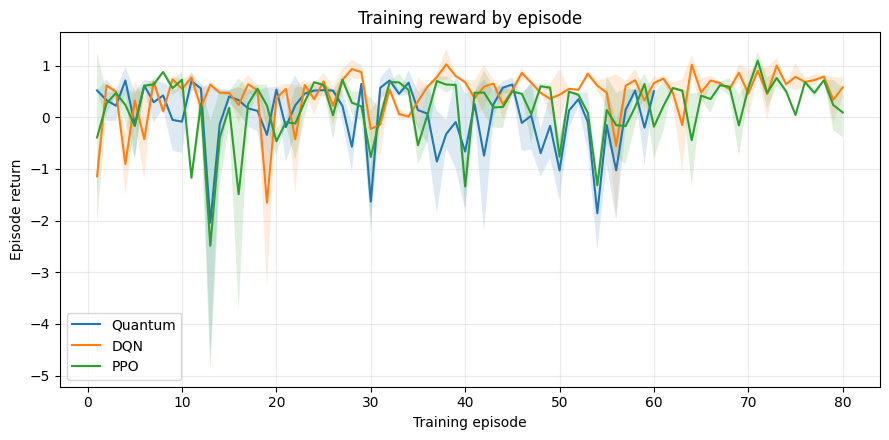

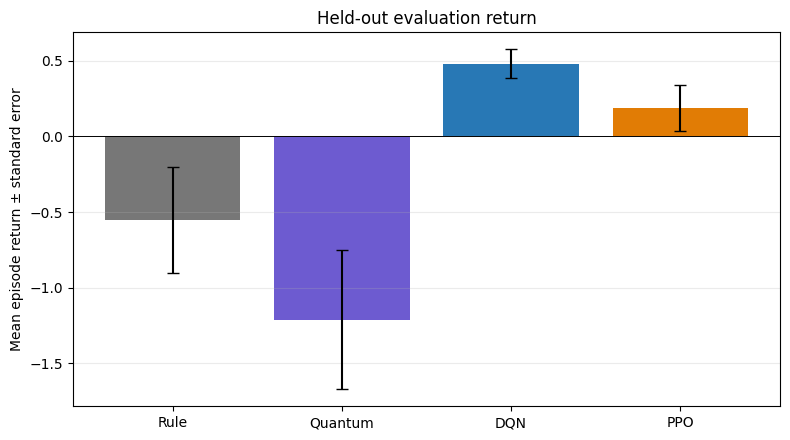

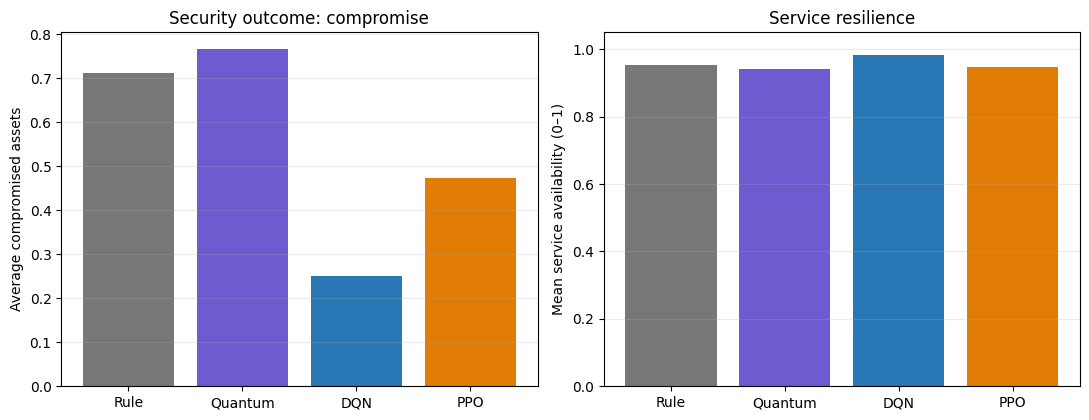

Saved tables and figures to quantum_cyber_defender_artifacts


In [14]:
def build_summary(results):
    rows=[]
    evaluation=results["evaluation"]
    methods=["Rule","Quantum","DQN","PPO"]
    for method in methods:
        frame=evaluation[evaluation.method==method]
        model=next((v for (m,_),v in results["models"].items() if m==method),None)
        sec=np.mean([v for (m,_),v in results["training_seconds"].items() if m==method]) if method!="Rule" else 0.
        rows.append({"method":method,"return_mean":frame["return"].mean(),"return_sd":frame["return"].std(ddof=1),
            "final_compromised_mean":frame.final_compromised.mean(),"mean_compromised":frame.mean_compromised.mean(),
            "availability_mean":frame.mean_availability.mean(),"action_cost_mean":frame.action_cost.mean(),
            "length_mean":frame.length.mean(),"termination_rate":frame.terminated.mean(),"training_seconds_mean":sec,
            "inference_ms":inference_ms(model,method) if method!="Rule" else inference_ms(None,"Rule")})
    return pd.DataFrame(rows)

summary=build_summary(results)
display(summary.round(3))

fig,ax=plt.subplots(figsize=(9,4.5))
for method, frames in results["training"].items():
    pooled=pd.concat(frames); grouped=pooled.groupby("episode")["return"]
    means=grouped.mean(); sem=grouped.sem()
    ax.plot(means.index,means.values,label=method)
    ax.fill_between(means.index,(means-sem).values,(means+sem).values,alpha=.15)
ax.set(title="Training reward by episode",xlabel="Training episode",ylabel="Episode return")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"training_reward.png",dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(8,4.5))
methods=["Rule","Quantum","DQN","PPO"]
means=[results["evaluation"].query("method == @m")["return"].mean() for m in methods]
sems=[results["evaluation"].query("method == @m")["return"].sem() for m in methods]
ax.bar(methods,means,yerr=sems,capsize=4,color=["#777777","#6d5bd0","#2878b5","#e17c05"])
ax.axhline(0,color="black",linewidth=.7); ax.set(title="Held-out evaluation return",ylabel="Mean episode return ± standard error")
ax.grid(axis="y",alpha=.25); fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"evaluation_return.png",dpi=160); plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,metric,title,ylabel in [(axes[0],"mean_compromised","Security outcome: compromise","Average compromised assets"),
                               (axes[1],"availability_mean","Service resilience","Mean service availability (0–1)")]:
    ax.bar(summary.method,summary[metric],color=["#777777","#6d5bd0","#2878b5","#e17c05"])
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(axis="y",alpha=.25)
    if metric=="availability_mean": ax.set_ylim(0,1.05)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"security_availability.png",dpi=160); plt.show()
summary.to_csv(ARTIFACT_DIR/"performance_summary.csv",index=False)
results["evaluation"].to_csv(ARTIFACT_DIR/"evaluation_episodes.csv",index=False)
for method, frames in results["training"].items(): pd.concat(frames).to_csv(ARTIFACT_DIR/f"{method.lower()}_training.csv",index=False)
print("Saved tables and figures to",ARTIFACT_DIR)

## Results interpretation

Interpret only values produced by executing the experiment cells. A positive difference in this small task is evidence about this simulator/configuration, not real-world security or quantum advantage. Report variation across independent training seeds as well as episode-level variation when making stronger claims; the default quick mode has only two training seeds and is exploratory.

**Fill in after execution:** “Under [configuration], [method] achieved [measured result and uncertainty] on [number] held-out episodes. This result [does/does not] support [carefully scoped statement]. Runtime was [measured values].” Do not claim a gain unless it is supported by the generated measurements and robust additional runs.

## Limitations and threats to validity

- **Prototype environment:** aggregate synthetic dynamics omit topology, identity, lateral movement, real incident response, and operational constraints. Simulator score does not imply real-world effectiveness.
- **Reward and model bias:** chosen weights encode one preference trade-off and may reward undesirable proxies. Alternative rewards can change rankings; threat dynamics are intentionally simple.
- **Quantum policy:** a small VQC may underfit, have high-variance gradients, train slowly, or lose to standard neural networks. Deeper circuits can make optimization difficult; barren plateaus can shrink gradients in some circuit families/scalings, but are not assumed inevitable here.
- **Simulation and shots:** analytic statevector-style simulation calculates ideal expectations. Finite shots add measurement noise and runtime. Neither models hardware noise by default.
- **No advantage claim:** demonstrating that a policy uses parameterized quantum gates is different from demonstrating quantum computational advantage. That would require a carefully controlled task, strong classical references, resource accounting, and repeatable evidence of an advantage not explained by implementation differences.
- **Fairness and confounds:** algorithms differ in on/off-policy learning, update counts, exploration, and sample efficiency. Training episodes are aligned approximately, not gradient updates or compute. Shared evaluation seeds and reward help, but do not remove all confounders.
- **Statistics/runtime:** small seed counts and machine-dependent timing are exploratory. Expand independent seeds, report confidence intervals, perform ablations, and compare equal interaction budgets and compute budgets before drawing conclusions.

## Conclusion and future research

The notebook provides a complete end-to-end prototype: a synthetic defender environment, a differentiable 4/6-qubit policy, REINFORCE updates, three baselines, tests, held-out evaluation, plots, and saved artifacts. Its scientific value is demonstrating and interrogating a hybrid RL pipeline—not predicting the best agent or asserting advantage.

Promising next steps: (1) replace aggregate dynamics with a validated, still-isolated cyber range and explicit partial-observation modeling; (2) conduct controlled encoding/depth/shot/noise ablations and resource-matched classical comparisons; (3) investigate safe RL or multi-agent defender/attacker scenarios with robust uncertainty and incident-response constraints.

## Interview preparation

### 60-second project pitch
“I built a reproducible CPU prototype for autonomous defense in a synthetic partially observed enterprise-network environment. A four-qubit variational circuit encodes compressed telemetry, measures observables, and produces a stochastic action policy trained through actual environment interaction with REINFORCE. I compare it with an interpretable rule policy, DQN, and PPO on common held-out seeds, measuring returns, compromise, availability, costs, and runtime. The purpose is to test feasibility and understand limitations; this toy simulator cannot establish operational effectiveness or quantum advantage.”

### Three-minute technical explanation
The environment keeps hidden asset compromise, containment, hardening, service availability, threat severity, resources, and noisy telemetry. It exposes eight normalized aggregate features and four discrete defensive actions. Each step applies defender action preconditions and costs, advances stochastic attacker dynamics, computes reward, and reports termination/truncation. The observation encoder uses all eight inputs through a trainable linear map into four bounded angles. PennyLane applies data rotations, layered trainable `RY`/`RZ` gates, and ring CNOT entanglement; Pauli-Z expectations go to a classical logits layer. Sampling from the softmax yields actions. REINFORCE uses discounted trajectory returns, a baseline-like normalization, log probabilities, and entropy regularization. DQN learns values with replay/target networks and epsilon-greedy exploration; PPO learns a clipped actor-critic from episode rollouts. All learned agents are frozen at evaluation and measured with the same held-out seeds. Analytic simulation is reproducible and avoids shot variance, but is not hardware execution; finite shots are configurable. Any claims are limited to measured behavior in this synthetic task.

### Architecture and design choices
- **Observation/action/learning flow:** hidden simulator state → bounded observed vector → policy distribution/value estimate → defensive action → stochastic transition/reward → trajectory/replay buffer → optimizer update.
- **Why investigate quantum RL?** It offers a principled way to study trainable quantum feature maps within sequential decision-making. This is a research question, not a promise of superior performance.
- **Why 4 qubits, optional 6?** Small enough for fast simulation and inspection, with an experimentable capacity change. The observation is projected to the qubit count, not truncated.
- **Why policy gradients for quantum?** A VQC naturally emits differentiable logits and categorical policies; REINFORCE is simple and compatible with trajectory returns, though higher variance than actor-critic methods.
- **Baselines:** rules use transparent thresholds; DQN estimates action values with replay and a target network; PPO optimizes a clipped actor-critic objective.
- **Encoding and action selection:** a learned classical projection compresses eight observed values to angles; measured expectations yield logits; categorical sampling explores during learning and argmax is used for deterministic evaluation.
- **Reward priorities:** reduce compromises/threat, preserve availability, reward useful containment/recovery, penalize resource usage and delayed reactions. The weights express assumptions and need sensitivity checks.
- **Leakage/fairness:** learned policies are tested on seeds not used for training; every method sees the same held-out seed list and reward. Action-dependent stochastic paths still diverge. Budgets and algorithms are not equal in compute cost.
- **Meaningful evidence:** repeated independent runs, statistically credible improvement on predeclared metrics, robustness to environment/reward variants, fair strong baselines, and resource accounting. A quantum advantage claim additionally needs evidence attributable to quantum computation.
- **Negative results:** failure to outperform classical baselines is informative about this ansatz/task/optimizer and the burden of simulation; it is not proof that all quantum approaches fail.
- **Open limitations:** synthetic environment, proxy rewards, small seed count, simple circuits, ideal simulator default, unequal algorithmic efficiency, and lack of real operational validation.

### Likely interview questions
1. **What is the observation?** Eight normalized aggregate features covering compromise, activity, availability, severity, resources, containment, recovery, and confidence.
2. **What does the circuit measure?** One Pauli-Z expectation per qubit, a value from -1 to 1.
3. **Why use a classical feature map?** There are more features than qubits; a trainable map incorporates all inputs into a compact angle encoding.
4. **How does learning change the circuit?** The sampled action log-probability is weighted by discounted returns; autodiff computes parameter gradients and Adam updates them.
5. **What is entanglement doing?** CNOTs create correlations between wires, allowing joint features beyond independent rotations.
6. **How does REINFORCE differ from DQN?** REINFORCE directly optimizes sampled action probabilities; DQN estimates action values and uses Bellman bootstrapping.
7. **Why entropy regularization?** It discourages premature deterministic collapse and supports exploration.
8. **Why PPO?** Its clipped probability ratio limits the size of each policy update and it uses a learned value baseline.
9. **Do the results show quantum advantage?** No. They test a quantum-parameterized policy on a classical simulator against selected baselines.
10. **What would you improve first?** Validate environment assumptions, increase independent seeds, test reward/encoding ablations, and compare under matched interactions and compute.

### Challenging follow-ups
1. **Does the classical projection undermine the quantum approach?** It makes this a hybrid model. Its purpose is dimensionally valid encoding; a fair study must compare alternate encoders and parameter-matched classical models.
2. **Why are results deterministic in analytic mode?** Given fixed seeds and deterministic operations, the simulator computes expectation values exactly; environment and policy training randomness are seeded. Wall-clock times remain noisy.
3. **How would finite shots affect gradients?** Measurements become stochastic estimates; variance rises and gradients may be noisier, often requiring more shots or altered learning rates. This setting should be separately evaluated, not conflated with ideal results.
4. **What is a fair computational comparison?** Report environment interactions, optimizer updates, parameter count, simulator calls, wall time, and hardware. There is no single budget that equalizes every algorithm.
5. **Could this policy be deployed on a SOC?** Not from this evidence. Deployment would require validated data, safety constraints, extensive testing, human oversight, adversarial robustness, and integration/security review.

### Future graduate research directions
1. Safe, risk-sensitive quantum/hybrid RL with uncertainty-aware policy constraints in validated cyber ranges.
2. Resource-matched comparisons of quantum data encodings, ansätze, noise models, and classical kernels across tasks with pre-registered metrics.
3. Multi-agent cyber defense with partial observability, causal threat modeling, and human-in-the-loop response policies.

### Glossary
- **Qubit:** two-level quantum system; computational basis measurement returns 0 or 1.
- **Superposition:** amplitude-weighted combination of basis states, with probabilistic measurement outcomes.
- **Rotation gate:** unitary transformation parameterized by an angle, such as `RY(θ)`.
- **CNOT:** controlled-not gate; flips a target conditional on the control and can entangle qubits.
- **Expectation value:** average measurement outcome, e.g. `⟨Z⟩`.
- **VQC:** trainable quantum circuit with classical parameters.
- **Feature encoding:** mapping classical data into quantum gate parameters/states.
- **Policy gradient:** gradient-based optimization of expected policy return.
- **Discounted return:** future reward sum with factor `γ^k`.
- **Shot:** one circuit execution and measurement sample.
- **Barren plateau:** a regime where gradients become very small, hindering optimization in some circuit/problem settings.

### Common misconceptions
- A superposition does not mean a quantum computer provides free parallel answers upon measurement.
- More qubits do not automatically mean a better policy or quantum advantage.
- Simulator speed does not predict quantum hardware speed.
- A learned policy is not safe merely because reward improves.
- A stochastic environment score is not a cybersecurity effectiveness guarantee.
- “Quantum RL” here means RL with a variational quantum policy; the complete training system is hybrid classical/quantum.

## References

1. **Bergholm, V. et al. (2018), “PennyLane: Automatic differentiation of hybrid quantum-classical computations.”** arXiv:1811.04968. [https://arxiv.org/abs/1811.04968](https://arxiv.org/abs/1811.04968). Introduces PennyLane's differentiable hybrid-programming approach.
2. **Schuld, M. & Killoran, N. (2019), “Quantum machine learning in feature Hilbert spaces.”** Physical Review Letters 122, 040504. DOI: [10.1103/PhysRevLett.122.040504](https://doi.org/10.1103/PhysRevLett.122.040504). Context for quantum feature maps and encoding.
3. **Cerezo, M. et al. (2021), “Variational quantum algorithms.”** Nature Reviews Physics 3, 625–644. DOI: [10.1038/s42254-021-00348-9](https://doi.org/10.1038/s42254-021-00348-9). Review of variational circuits and optimization challenges.
4. **Williams, R. J. (1992), “Simple statistical gradient-following algorithms for connectionist reinforcement learning.”** Machine Learning 8, 229–256. DOI: [10.1007/BF00992696](https://doi.org/10.1007/BF00992696). Original REINFORCE policy-gradient method.
5. **Mnih, V. et al. (2015), “Human-level control through deep reinforcement learning.”** Nature 518, 529–533. DOI: [10.1038/nature14236](https://doi.org/10.1038/nature14236). Canonical DQN paper.
6. **Schulman, J. et al. (2017), “Proximal Policy Optimization Algorithms.”** arXiv:1707.06347. [https://arxiv.org/abs/1707.06347](https://arxiv.org/abs/1707.06347). PPO clipped policy objective and implementation details.
7. **Microsoft (2021), CyberBattleSim.** [https://github.com/microsoft/CyberBattleSim](https://github.com/microsoft/CyberBattleSim). Open-source research simulator reference; this notebook does not reproduce it.
8. **McClean, J. R. et al. (2018), “Barren plateaus in quantum neural network training landscapes.”** Nature Communications 9, 4812. DOI: [10.1038/s41467-018-07090-4](https://doi.org/10.1038/s41467-018-07090-4). Analyzes vanishing-gradient regimes for some quantum circuit landscapes.
9. **Henderson, P. et al. (2018), “Deep reinforcement learning that matters.”** Proceedings of AAAI 32(1). DOI: [10.1609/aaai.v32i1.11694](https://doi.org/10.1609/aaai.v32i1.11694). Discusses reproducibility, seeds, and evaluation in RL.
10. **PennyLane documentation.** [https://docs.pennylane.ai/](https://docs.pennylane.ai/). Device, QNode, Torch interface, and simulator documentation.
11. **Gymnasium documentation.** [https://gymnasium.farama.org/](https://gymnasium.farama.org/). Environment API and environment checker.
12. **PyTorch documentation.** [https://pytorch.org/docs/stable/](https://pytorch.org/docs/stable/). Autodifferentiation, distributions, and neural-network API.

Citations provide conceptual background, not a claim that this notebook reproduces any cited experiment.

## Save and download artifacts

The experiment cell saves CSV tables and PNG figures to the notebook session's `quantum_cyber_defender_artifacts/` directory. Models and configuration can also be serialized for later loading. In Colab, use the download helper below to create a ZIP and download it, or use the Files sidebar. Save the notebook through **File → Download → Download `.ipynb`**. Restarting a Colab session clears local runtime files, so download artifacts before closing.

In [15]:
# Save trained models and the exact configuration for reproducibility.
model_payload={}
for (method,seed),model in results["models"].items():
    model_payload[f"{method}_seed_{seed}"]={k:v.detach().cpu() for k,v in model.state_dict().items()}
torch.save(model_payload,ARTIFACT_DIR/"model_state_dicts.pt")
with open(ARTIFACT_DIR/"experiment_config.json","w") as f:
    json.dump(asdict(CONFIG),f,indent=2)

# Example loading: rebuild the same architecture before loading a state_dict.
example_model=QuantumPolicy(n_qubits=CONFIG.n_qubits,depth=CONFIG.circuit_depth,shots=CONFIG.shots)
first_q_seed=CONFIG.seeds[0]
example_model.load_state_dict(results["models"][("Quantum",first_q_seed)].state_dict())
print("Reload check:", all(torch.equal(a,b) for a,b in zip(example_model.state_dict().values(),results["models"][("Quantum",first_q_seed)].state_dict().values())))

import shutil
zip_path=shutil.make_archive(str(ARTIFACT_DIR),"zip",root_dir=ARTIFACT_DIR)
print("Artifact archive:",zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Outside Colab, retrieve the archive from the printed path.")

# Optional: download individual files in Colab:
# from google.colab import files
# files.download("quantum_cyber_defender_artifacts/performance_summary.csv")

Reload check: True
Artifact archive: /content/quantum_cyber_defender_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>